In [3]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
# from sklearn.metrics import mean_squared_errorq
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")

## Linear Regression

In [4]:
data = pd.read_csv(filepath_or_buffer = "data_lin.csv", header=None)
X = np.array(data.iloc[:,:-1])
y = np.array(data.iloc[:,-1])

In [5]:
data

,0,1
0,0.45478,3.18270
1,-0.31160,0.34708
2,0.94642,5.00180
3,0.33790,2.75020
4,0.23853,2.38260
...,...,...
195,-0.32393,0.30145
196,-0.79467,-1.44030
197,0.40179,2.98660
198,-1.81770,-5.22540


### Train-Test Split

In [6]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [7]:
# from numpy._core.fromnumeric import mean
def data_matrix(X, y, norm_type):
    if norm_type == "max-min":
        min_value = X.min(axis = 0)
        max_value = X.max(axis = 0)
        X = (X - X.min(axis = 0)) / (X.max(axis = 0) - X.min(axis = 0))
    if norm_type == "z-score":
        mean_value = X.mean(axis = 0)
        std_value = X.std(axis = 0)
        X = (X - X.mean(axis = 0)) / X.std(axis = 0)
    m,n = np.shape(X)
    X_data = [np.ones(m)]
    for i in range(len(X.T)):
        X_data.append(X.T[i])
    X = np.array(X_data).T
    if norm_type == "max-min":
        return X, y, min_value, max_value
    if norm_type == "z-score":
        return X, y, mean_value, std_value



def data_matrix_without_appending_ones(X, y, norm_type):
    if norm_type == "max-min":
        min_value = X.min(axis = 0)
        max_value = X.max(axis = 0)
        X = (X - X.min(axis = 0)) / (X.max(axis = 0) - X.min(axis = 0))
        return X, y, min_value, max_value
    if norm_type == "z-score":
        mean_value = X.mean(axis = 0)
        std_value = X.std(axis = 0)
        X = (X - X.mean(axis = 0)) / X.std(axis = 0)
        return X, y, mean_value, std_value


def RMSE(weight, X, Y):
    sum = 0
    N = len(Y)
    for i in range(len(Y)):
        sum += (Y[i] - np.dot(weight, X[i].T))**2
    return 1/N * float(sum)**0.5



### Data Normalization

In [8]:
X_train_norm, y_train_norm, min_value, max_value = data_matrix(X_train, y_train, 'max-min')
X_test_norm = (X_test - min_value) / (max_value - min_value)

In [9]:
# X_test_norm.shape
X_train_norm

array([[1.        , 0.51491633],
       [1.        , 0.56066739],
       [1.        , 0.48273778],
       [1.        , 0.60162392],
       [1.        , 0.45596594],
       [1.        , 0.41694623],
       [1.        , 0.68569165],
       [1.        , 0.22497277],
       [1.        , 0.34610952],
       [1.        , 0.35520547],
       [1.        , 0.47423289],
       [1.        , 0.73207248],
       [1.        , 0.21887316],
       [1.        , 0.5950906 ],
       [1.        , 0.51288444],
       [1.        , 0.5367779 ],
       [1.        , 0.45037132],
       [1.        , 0.57325874],
       [1.        , 0.75496584],
       [1.        , 0.6392732 ],
       [1.        , 0.61147836],
       [1.        , 0.37470245],
       [1.        , 0.37888702],
       [1.        , 0.60449153],
       [1.        , 0.14910387],
       [1.        , 1.        ],
       [1.        , 0.66496089],
       [1.        , 0.22338845],
       [1.        , 0.56355679],
       [1.        , 0.59123874],
       [1.

### Direct Method

In [10]:
X_2d = X_train_norm
# X_2d = X_app
W = np.linalg.inv(np.matmul(X_2d.T, X_2d)) @ (np.matmul(X_2d.T, y_train_norm.reshape(-1, 1)))
W

array([[-7.48841072],
       [18.68314414]])

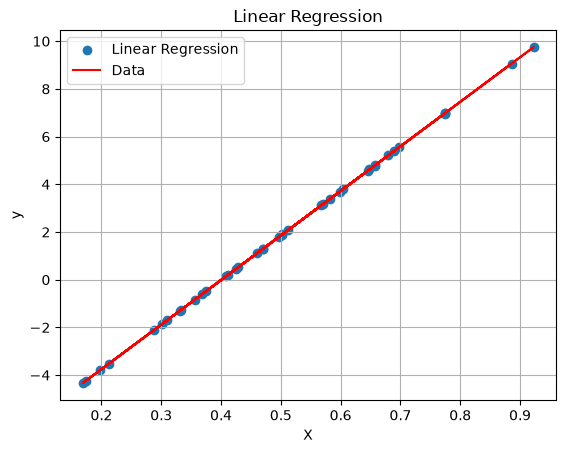

In [11]:
plt.scatter(X_test_norm,y_test)
plt.plot(X_test_norm, W[0] + W[1]*X_test_norm, c = 'r')
plt.xlabel('X')
plt.ylabel('y')
plt.title('Linear Regression')
plt.grid()
plt.legend(['Linear Regression', 'Data'])
plt.show()

In [12]:
X, y, min_value, max_value = data_matrix(X,y, norm_type = 'max-min')
m,n = np.shape(X)
print("Number of Data points: ",m)
print("Number of features: ",n)

Number of Data points:  200
Number of features:  2


In [13]:
weight = np.random.rand(n)
# weight
RMSE(weight, X,y)
# np.dot(weight[n], X[0].T)

0.2425851917874168

In [14]:

import numpy as np
import matplotlib.pyplot as plt

def linear_regression(
    X,
    y,
    tolerance=1e-5,
    alpha=0.01,
    gradient_type="stochastic",
    max_iters=10000
):


    m, n = X.shape
    weight_new = np.ones(n)
    weights = []
    Errors = []

    for epoch in range(max_iters):
        weight_old = weight_new.copy()

        if gradient_type == "batch":
            predictions = X @ weight_old
            errors = y - predictions
            gradient = (X.T @ errors) / m

            weight_new = weight_old + alpha * gradient

        elif gradient_type == "stochastic":
            for i in np.random.permutation(m):
                error = y[i] - np.dot(weight_new, X[i])
                gradient = error * X[i]
                weight_new = weight_new + alpha * gradient

        weights.append(weight_new.copy())
        Errors.append(RMSE(weight_new, X, y))

        if np.linalg.norm(weight_new - weight_old) < tolerance:
            break

    plt.plot(range(1, len(Errors) + 1), Errors)
    plt.xlabel("Epoch")
    plt.ylabel("RMSE")
    plt.title(f"Linear Regression ({gradient_type})")
    plt.grid(True)
    plt.show()

    return weight_new, weights, Errors


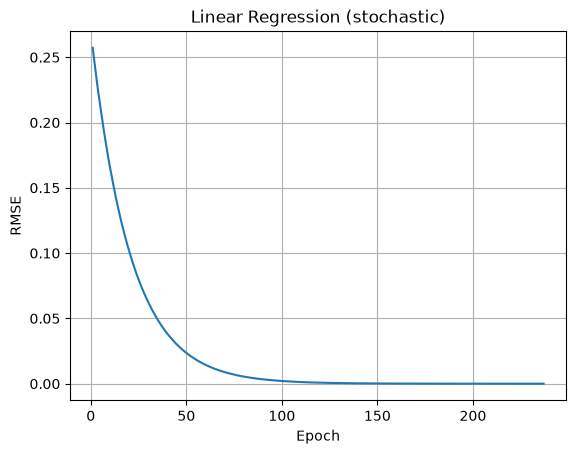

In [15]:
weight_new, weights, Errors = linear_regression(X_train_norm, y_train_norm, gradient_type = 'stochastic')

In [16]:
weight_new

array([-7.48833371, 18.68297409])

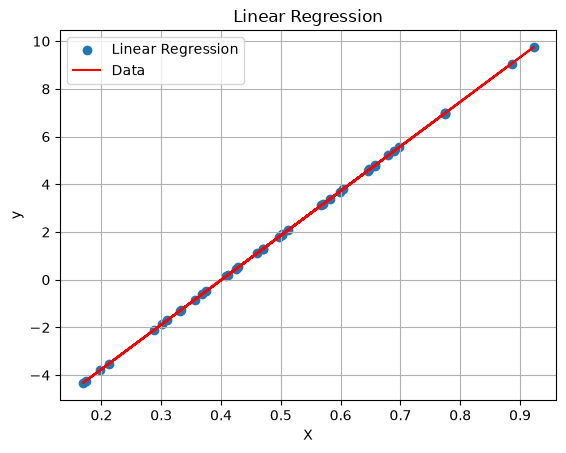

In [17]:
plt.scatter(X_test_norm,y_test)
plt.plot(X_test_norm, weight_new[0] + weight_new[1]*X_test_norm, c = 'r')
plt.xlabel('X')
plt.ylabel('y')
plt.title('Linear Regression')
plt.grid()
plt.legend(['Linear Regression', 'Data'])
plt.show()

### Using Packages

In [35]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, root_mean_squared_error
from sklearn.model_selection import train_test_split


def linear_regression(X,y):

    X = np.asarray(X, dtype=float)
    y = np.asarray(y, dtype=float).reshape(-1)

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=42
    )

    model = LinearRegression()
    model.fit(X_train, y_train)

    # y_train_pred = model.predict(X_train)
    y_pred = model.predict(X_test)

    rmse = root_mean_squared_error(y_test, y_pred)

    print("Weights:", model.coef_)
    print("Bias:", model.intercept_)
    print("RMSE:", rmse)
    print("R² score:", model.score(X_test, y_test))

    plt.scatter(X_test[:, 0], y_test, label="Actual values")
    plt.scatter(X_test[:, 0], y_pred, label="Predicted values")
    plt.xlabel("X")
    plt.ylabel("y")
    plt.title("Linear Regression")
    plt.grid(True)
    plt.legend()

    # plt.scatter(y_test, y_pred)
    # plt.xlabel("Actual values")
    # plt.ylabel("Predicted values")
    # plt.title("Linear Regression: Actual vs Predicted")
    # plt.grid(True)
    plt.show()

    return model

Weights: [3.69999884]
Bias: 1.4999964662639351
RMSE: 6.99631108874455e-05
R² score: 0.9999999996104709


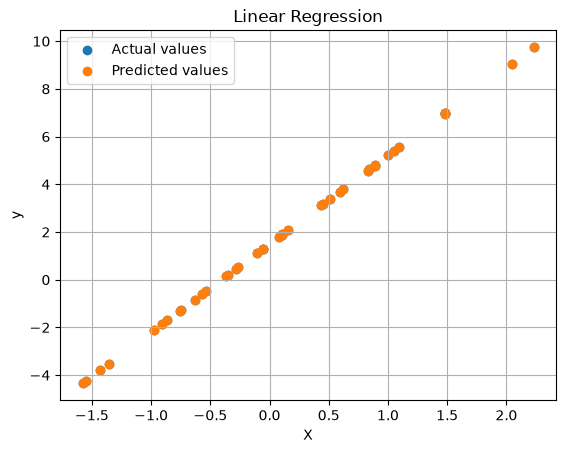

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[3.7]
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,1.5
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](1,)",[12.32]


In [36]:
data = pd.read_csv(filepath_or_buffer = "data_lin.csv", header=None)
X = np.array(data.iloc[:,:-1])
y = np.array(data.iloc[:,-1])
linear_regression(X,y)

## Logistic Regression

In [34]:

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd


def sigmoid(z):
    # Numerically stable sigmoid
    z = np.asarray(z, dtype=float)
    result = np.empty_like(z)
    positive = z >= 0

    result[positive] = 1 / (1 + np.exp(-z[positive]))

    exp_z = np.exp(z[~positive])
    result[~positive] = exp_z / (1 + exp_z)

    return result


def binary_cross_entropy(y, probabilities):
    eps = 1e-15
    probabilities = np.clip(probabilities, eps, 1 - eps)

    return -np.mean(
        y * np.log(probabilities)
        + (1 - y) * np.log(1 - probabilities)
    )


def logistic_regression(
    X,
    y,
    tolerance=1e-5,
    alpha=0.01,
    gradient_type="batch",
    max_iters=500
):

    m, n = X.shape

    weights = np.zeros(n)

    weight_history = []
    loss_history = []

    for epoch in range(max_iters):
        old_weights = weights.copy()

        if gradient_type == "batch":
            probabilities = sigmoid(X @ weights)
            errors = probabilities - y

            dw = (X.T @ errors) / m

            weights -= alpha * dw

        else:  # Stochastic gradient descent
            for i in np.random.permutation(m):
                probability = sigmoid(
                    np.dot(X[i], weights)
                )

                error = probability - y[i]

                weights -= alpha * error * X[i]
                # bias -= alpha * error

        probabilities = sigmoid(X @ weights)
        loss = binary_cross_entropy(y, probabilities)

        weight_history.append(weights.copy())
        loss_history.append(loss)

        change = np.sqrt(
            np.sum((weights - old_weights) ** 2)
             ** 2
        )

        if change < tolerance:
            break

    plt.plot(range(1, len(loss_history) + 1), loss_history)
    plt.xlabel("Epoch")
    plt.ylabel("Binary cross-entropy")
    plt.title(f"Logistic Regression ({gradient_type})")
    plt.grid(True)
    plt.show()

    return weights, weight_history, loss_history


def predict_proba(X, weights, bias):
    X = np.asarray(X, dtype=float)
    return sigmoid(X @ weights + bias)


def predict(X, weights, bias, threshold=0.5):
    return (predict_proba(X, weights, bias) >= threshold).astype(int)


In [22]:
data = pd.read_csv(filepath_or_buffer = "data_logi.csv", header=None)
# X,y = data_normalize(data, 'max-min')
X = np.array(data.iloc[:,:-1])
y = np.array(data.iloc[:,-1])

In [23]:
data

,0,1,2
0,6,32,1
1,26,39,1
2,2,38,1
3,25,39,1
4,3,35,1
...,...,...,...
195,47,17,-1
196,24,27,-1
197,18,18,-1
198,19,7,-1


In [24]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [25]:
# X_train_norm, y_train_norm, min_value, max_value = data_matrix(X_train, y_train, 'max-min')
X_train_norm, y_train_norm, mean_value, std_value = data_matrix(X_train, y_train, 'z-score')
# X_test_norm = (X_test - min_value) / (max_value - min_value)
X_test_norm = (X_test - mean_value) / (std_value)

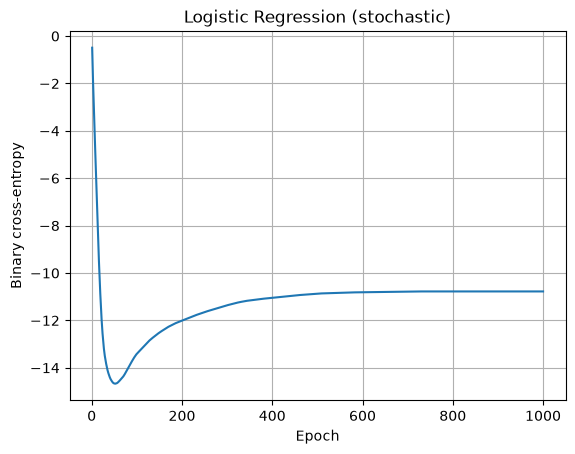

In [26]:
weights, weight_history, loss_history = logistic_regression(X_train_norm, y_train_norm, gradient_type = 'stochastic', max_iters=1000)

In [27]:
weights,

(array([-486.56435866, -625.42252119,  529.55444769]),)

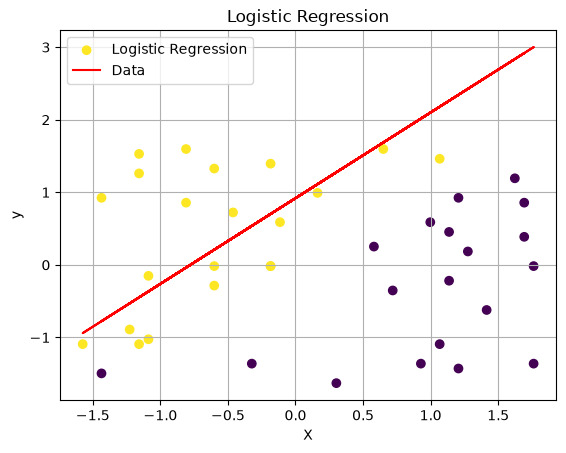

In [28]:
plt.scatter(X_test_norm[:,0],X_test_norm[:,1], c = y_test)
plt.plot(X_test_norm[:,0], (-weights[0] - weights[1] * X_test_norm[:,0])/weights[2], c = 'r')
plt.xlabel('X')
plt.ylabel('y')
plt.title('Logistic Regression')
plt.grid()
plt.legend(['Logistic Regression', 'Data'])
plt.show()

In [37]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay,
    log_loss
)


def logistic_regression(X,y):
    

    X = np.asarray(X, dtype=float)
    y = np.asarray(y).reshape(-1)

    X_train, X_test, y_train, y_test = train_test_split(
        X,
        y,
        test_size=0.2,
        random_state=42,
        stratify=y
    )

    model = LogisticRegression(
        max_iter=1000,
        solver="lbfgs"
    )

    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)

    print("Weights:", model.coef_)
    print("Bias:", model.intercept_)
    print("Classes:", model.classes_)
    print("Accuracy:", accuracy_score(y_test, y_pred))
    print("Log loss:", log_loss(y_test, y_prob))
    print("\nClassification Report:")
    print(classification_report(y_test, y_pred))

    cm = confusion_matrix(y_test, y_pred)

    ConfusionMatrixDisplay.from_predictions(y_test, y_pred)
    plt.title("Logistic Regression: Confusion Matrix")
    plt.show()

    return model

Weights: [[-1.44963382  1.24784605]]
Bias: [0.93556889]
Classes: [-1  1]
Accuracy: 0.975
Log loss: 0.03255007053677118

Classification Report:
              precision    recall  f1-score   support

          -1       1.00      0.95      0.97        20
           1       0.95      1.00      0.98        20

    accuracy                           0.97        40
   macro avg       0.98      0.97      0.97        40
weighted avg       0.98      0.97      0.97        40



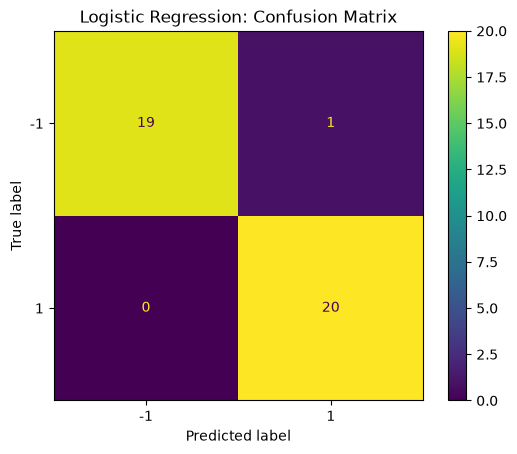

,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use i

In [39]:
data = pd.read_csv(filepath_or_buffer = "data_logi.csv", header=None)
# X,y = data_normalize(data, 'max-min')
X = np.array(data.iloc[:,:-1])
y = np.array(data.iloc[:,-1])
logistic_regression(X,y)

In [40]:
weights

array([-486.56435866, -625.42252119,  529.55444769])